# Homework 1 - Problem 5: Custom losses with automatic differentiation

We use PyTorch (autodiff + `torch.optim.SGD`) to implement
- **Classification** (Breast Cancer Wisconsin): logistic regression and probit regression with binary cross-entropy loss.
- **Regression** (ALE dataset): linear regression with squared-error loss and with the Student-t (nu = 5) negative log-likelihood.

Each model is compared with its scikit-learn baseline.

## Step 1: Imports and settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.distributions import Normal, StudentT

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_absolute_error

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
EPS = 1e-7  # clipping constant for probabilities

# Part A: Classification (Breast Cancer Wisconsin)

## Step 2: Load data, split 80/20, standardize
Features are standardized with statistics from the training set so that plain SGD converges.

In [2]:
data = load_breast_cancer()
Xc, yc = data.data, data.target
print(Xc.shape, np.bincount(yc))

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=SEED, stratify=yc)

scaler_c = StandardScaler().fit(Xc_train)
Xc_train_s = scaler_c.transform(Xc_train)
Xc_test_s = scaler_c.transform(Xc_test)

Xc_train_t = torch.tensor(Xc_train_s, dtype=torch.float32)
Xc_test_t = torch.tensor(Xc_test_s, dtype=torch.float32)
yc_train_t = torch.tensor(yc_train, dtype=torch.float32)
yc_test_t = torch.tensor(yc_test, dtype=torch.float32)

(569, 30) [212 357]


## Step 3: Baseline - scikit-learn logistic regression

In [3]:
sk_clf = LogisticRegression(max_iter=1000)
sk_clf.fit(Xc_train_s, yc_train)
baseline_acc = accuracy_score(yc_test, sk_clf.predict(Xc_test_s))
print(f"sklearn logistic regression test accuracy: {baseline_acc:.4f}")

sklearn logistic regression test accuracy: 0.9825


## Step 4: Generic SGD training helper

`train` runs mini-batch SGD with `torch.optim.SGD` on a list of parameters, given a `forward` function and a `loss_fn(pred, y)`.
It records the full-training-set loss after every epoch.

In [4]:
def train(forward, params, loss_fn, X, y, lr, epochs, batch_size=32, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.SGD(params, lr=lr)
    n = X.shape[0]
    history = []
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(forward(X[idx]), y[idx])
            loss.backward()
            opt.step()
        with torch.no_grad():
            history.append(loss_fn(forward(X), y).item())
    return history

def bce_loss(p, y):
    p = p.clamp(EPS, 1 - EPS)  # avoid log(0)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

def init_params(d):
    w = torch.zeros(d, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    return w, b

## Step 5 (a): Logistic regression, f(x) = sigmoid(w^T x + b), BCE loss

In [5]:
w_lr, b_lr = init_params(Xc_train_t.shape[1])

def logistic_forward(X):
    return torch.sigmoid(X @ w_lr + b_lr)

hist_lr = train(logistic_forward, [w_lr, b_lr], bce_loss, Xc_train_t, yc_train_t,
                lr=0.1, epochs=200)

with torch.no_grad():
    pred_lr = (logistic_forward(Xc_test_t) >= 0.5).numpy().astype(int)
acc_lr = accuracy_score(yc_test, pred_lr)
print(f"Logistic (autodiff + SGD) test accuracy: {acc_lr:.4f}  (baseline {baseline_acc:.4f})")
print(f"Final training loss: {hist_lr[-1]:.4f}")

Logistic (autodiff + SGD) test accuracy: 0.9825  (baseline 0.9825)
Final training loss: 0.0473


## Step 6 (b): Probit regression, f(x) = Phi(w^T x + b), BCE loss

`Phi` is the standard normal CDF (`torch.distributions.Normal(0, 1).cdf`).

In [6]:
std_normal = Normal(torch.tensor(0.0), torch.tensor(1.0))
w_pr, b_pr = init_params(Xc_train_t.shape[1])

def probit_forward(X):
    return std_normal.cdf(X @ w_pr + b_pr)

hist_pr = train(probit_forward, [w_pr, b_pr], bce_loss, Xc_train_t, yc_train_t,
                lr=0.1, epochs=200)

with torch.no_grad():
    pred_pr = (probit_forward(Xc_test_t) >= 0.5).numpy().astype(int)
acc_pr = accuracy_score(yc_test, pred_pr)
print(f"Probit (autodiff + SGD) test accuracy: {acc_pr:.4f}  (baseline {baseline_acc:.4f})")
print(f"Final training loss: {hist_pr[-1]:.4f}")

Probit (autodiff + SGD) test accuracy: 0.9825  (baseline 0.9825)
Final training loss: 0.0419


## Step 7: Training curves and classification summary

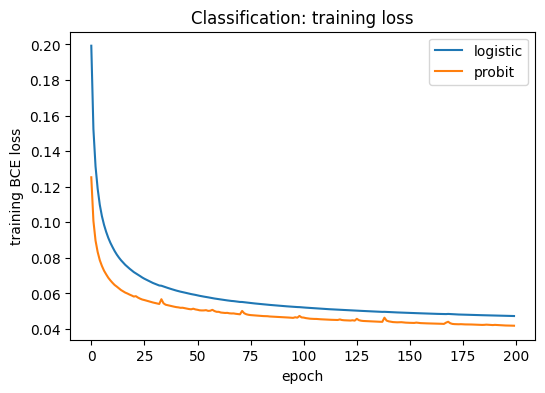

,test accuracy
sklearn LogisticRegression (baseline),0.982456
Logistic (autodiff + SGD),0.982456
Probit (autodiff + SGD),0.982456


In [7]:
plt.figure(figsize=(6, 4))
plt.plot(hist_lr, label="logistic")
plt.plot(hist_pr, label="probit")
plt.xlabel("epoch")
plt.ylabel("training BCE loss")
plt.legend()
plt.title("Classification: training loss")
plt.show()

pd.DataFrame({"test accuracy": {
    "sklearn LogisticRegression (baseline)": baseline_acc,
    "Logistic (autodiff + SGD)": acc_lr,
    "Probit (autodiff + SGD)": acc_pr,
}})

# Part B: Regression (ALE dataset)

## Step 8: Load data, split 80/20, standardize features
Same features and seed as Problem 4: the first 4 columns predict `ale`. Only the features are standardized, so MAE stays in the original units of `ale`.

In [8]:
df = pd.read_csv("../P4/ale.csv")
df.columns = [c.strip().lower() for c in df.columns]
feature_cols = df.columns[:4].tolist()
print("Features:", feature_cols)

Xr = df[feature_cols].values
yr = df["ale"].values
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=SEED)

scaler_r = StandardScaler().fit(Xr_train)
Xr_train_s = scaler_r.transform(Xr_train)
Xr_test_s = scaler_r.transform(Xr_test)

Xr_train_t = torch.tensor(Xr_train_s, dtype=torch.float32)
Xr_test_t = torch.tensor(Xr_test_s, dtype=torch.float32)
yr_train_t = torch.tensor(yr_train, dtype=torch.float32)
yr_test_t = torch.tensor(yr_test, dtype=torch.float32)
print(Xr_train_t.shape, Xr_test_t.shape)

Features: ['anchor_ratio', 'trans_range', 'node_density', 'iterations']
torch.Size([85, 4]) torch.Size([22, 4])


## Step 9: Baseline - scikit-learn linear regression (test MAE)

In [9]:
sk_reg = LinearRegression().fit(Xr_train_s, yr_train)
baseline_mae = mean_absolute_error(yr_test, sk_reg.predict(Xr_test_s))
print(f"sklearn linear regression test MAE: {baseline_mae:.4f}")
print("coefficients:", sk_reg.coef_, "intercept:", sk_reg.intercept_)

sklearn linear regression test MAE: 0.1921
coefficients: [-0.0539914  -0.0717484  -0.29283998 -0.2139092 ] intercept: 1.018214452082353


## Step 10 (a): Linear regression with squared-error loss

f(x) = w^T x + b, L = (y - f(x))^2, minimized with SGD.

In [10]:
def mse_loss(pred, y):
    return ((y - pred) ** 2).mean()

w_mse, b_mse = init_params(Xr_train_t.shape[1])

def linear_forward_mse(X):
    return X @ w_mse + b_mse

hist_mse = train(linear_forward_mse, [w_mse, b_mse], mse_loss, Xr_train_t, yr_train_t,
                 lr=0.01, epochs=300, batch_size=16)

with torch.no_grad():
    pred_mse = linear_forward_mse(Xr_test_t).numpy()
mae_mse = mean_absolute_error(yr_test, pred_mse)
print(f"Linear regression + MSE (autodiff + SGD) test MAE: {mae_mse:.4f}  (baseline {baseline_mae:.4f})")
print("weights:", w_mse.detach().numpy(), "bias:", b_mse.item())

Linear regression + MSE (autodiff + SGD) test MAE: 0.1917  (baseline 0.1921)
weights: [-0.05401375 -0.07168495 -0.29535583 -0.21376826] bias: 1.018962025642395


## Step 11 (b): Linear regression with Student-t negative log-likelihood (nu = 5)

L = -log p(y - f(x) | nu = 5), using `torch.distributions.StudentT(df=5).log_prob`. The heavier tails down-weight large residuals.

In [11]:
t_dist = StudentT(df=torch.tensor(5.0))

def t_nll_loss(pred, y):
    return -t_dist.log_prob(y - pred).mean()

w_t, b_t = init_params(Xr_train_t.shape[1])

def linear_forward_t(X):
    return X @ w_t + b_t

hist_t = train(linear_forward_t, [w_t, b_t], t_nll_loss, Xr_train_t, yr_train_t,
               lr=0.05, epochs=300, batch_size=16)

with torch.no_grad():
    pred_t = linear_forward_t(Xr_test_t).numpy()
mae_t = mean_absolute_error(yr_test, pred_t)
print(f"Linear regression + Student-t NLL (autodiff + SGD) test MAE: {mae_t:.4f}  (baseline {baseline_mae:.4f})")
print("weights:", w_t.detach().numpy(), "bias:", b_t.item())

Linear regression + Student-t NLL (autodiff + SGD) test MAE: 0.1878  (baseline 0.1921)
weights: [-0.05471736 -0.06953223 -0.28979212 -0.20914097] bias: 1.013263463973999


## Step 12: Regression training curves and summary

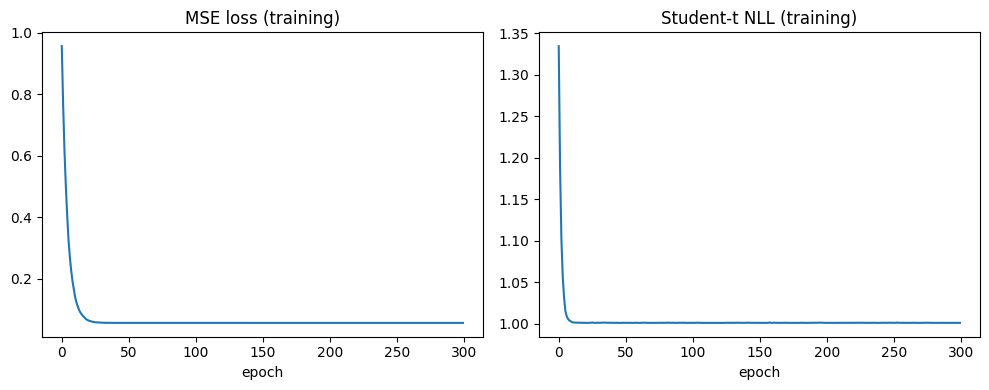

,test MAE
sklearn LinearRegression (baseline),0.192072
Linear + MSE (autodiff + SGD),0.191689
"Linear + Student-t NLL, nu=5 (autodiff + SGD)",0.187810


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(hist_mse)
axes[0].set_title("MSE loss (training)")
axes[0].set_xlabel("epoch")
axes[1].plot(hist_t)
axes[1].set_title("Student-t NLL (training)")
axes[1].set_xlabel("epoch")
plt.tight_layout()
plt.show()

pd.DataFrame({"test MAE": {
    "sklearn LinearRegression (baseline)": baseline_mae,
    "Linear + MSE (autodiff + SGD)": mae_mse,
    "Linear + Student-t NLL, nu=5 (autodiff + SGD)": mae_t,
}})

## Step 13: Conclusions

**Classification (Breast Cancer, 114 test points).** The scikit-learn logistic regression baseline reaches a test accuracy of 0.9825. Logistic regression trained with autodiff and SGD on the binary cross-entropy loss matches it exactly (0.9825, final training loss 0.0473), as does probit regression (0.9825, final training loss 0.0419). The two link functions, sigmoid and the normal CDF, are both smooth monotone maps to (0, 1) and give nearly the same decision boundary on standardized features, so the accuracies coincide. Probit reaches a slightly lower training loss, but this does not translate into a different test accuracy. Clipping the probabilities to [1e-7, 1 - 1e-7] avoided any numerical problems in the logarithms.

**Regression (ALE, 22 test points).** The scikit-learn linear regression baseline has a test MAE of 0.1921. Linear regression trained with SGD on the squared-error loss gives 0.1917 with weights almost identical to the closed-form solution, which confirms that SGD converges to the same minimizer. Using the Student-t negative log-likelihood with nu = 5 gives a slightly lower test MAE of 0.1878, with slightly different weights, because the heavy-tailed loss gives less weight to large residuals. This is consistent with Problem 4, where the residuals were right-skewed and heavy-tailed rather than normal.

**Caveat.** The t-loss improvement (0.1921 -> 0.1878) is small and the test set has only 22 points, so we cannot claim it is a significant gain. The main takeaways are that automatic differentiation lets us swap in custom losses (BCE with different links, Gaussian vs. Student-t noise) without deriving gradients by hand, and that the resulting models match or slightly improve on the scikit-learn baselines.